# Scattering from a Core–Shell Cylinder in FDTDX

A core–shell particle has two layers: an inner core made of one material and a shell of another material around it. Particles like this are common in nanophotonics. A gold shell around a silica core (a "nanoshell") has a plasmon resonance that moves with the shell thickness, so it can be tuned from the visible into the near-infrared. Quantum dots are usually coated with a second semiconductor to make them brighter and more stable. Dielectric core–shell particles can be designed to scatter light mostly in one direction, or to scatter very little at a chosen wavelength.

In all of these cases the optical response depends on both materials and on how the radius is divided between core and shell. The ratio of core size to shell thickness gives an extra design parameter, so the response can be changed without changing the materials.

This notebook looks at the simplest version of the problem: an infinitely long cylinder with a core of radius $a$ and permittivity $\varepsilon_1$, surrounded by a shell of outer radius $b$ and permittivity $\varepsilon_2$, sitting in vacuum. A plane wave travels along $x$ with its electric field along the cylinder axis ($z$). Nothing changes along $z$, so the problem is effectively two-dimensional and a simulation is cheap.

We compute how strongly the cylinder scatters and absorbs light. This is expressed as an efficiency $Q$, the cross section divided by the geometric width $2b$ of the cylinder. For example, $Q_{sca} = 1$ means the cylinder scatters as much power as falls on its geometric width. The extinction efficiency is the sum, $Q_{ext} = Q_{sca} + Q_{abs}$.

The notebook has two parts:

1. **Analytic reference.** Mie theory gives the exact answer for this geometry. We implement it with `scipy`, test it, and use it to look at an example.
2. **FDTD simulation.** We run the same problem with `fdtdx` and compare the spectra and the near field against the analytic result.

The math behind the analytic solution is collected in the [Appendix](#Appendix) at the end.

## Part 1: Analytic reference

Scattering from a cylinder can be solved exactly with Mie theory. The incident plane wave is written as a sum of cylindrical waves, and the amplitudes of the scattered waves are fixed by requiring that the fields match at every interface. For a solid cylinder this gives a closed formula. A core–shell cylinder has two interfaces, so for each angular order we have to solve a small $4\times4$ linear system instead.

The cell defines the efficiencies $Q_{sca}$, $Q_{abs}$ and $Q_{ext}$ as a function of wavelength, and a function for the field around the particle. It also contains the solid-cylinder version, which we only use for the checks below. The derivation is in the [Appendix](#Appendix), but it isn't needed to follow the rest of the notebook.

In [3]:
from dataclasses import dataclass

import numpy as np
import scipy.special as sp
import matplotlib.pyplot as plt

# --- single-material (homogeneous) cylinder ---
# Used only to validate the core-shell formulas against known limiting cases.
def _mie_cyl_coeffs(x, m, nmax):
    n = np.arange(nmax + 1)
    mx = m * x
    Jx, Jpx = sp.jv(n, x), sp.jvp(n, x)
    Jmx, Jpmx = sp.jv(n, mx), sp.jvp(n, mx)
    Hx, Hpx = sp.hankel1(n, x), sp.h1vp(n, x)
    a = (m * Jpmx * Jx - Jmx * Jpx) / (Jmx * Hpx - m * Jpmx * Hx)
    d = (Jx + a * Hx) / Jmx
    return a, d


def mie_cylinder_Q(wls, radius, eps, eps_med=1.0):
    wls = np.asarray(wls, float)
    m = np.sqrt(np.broadcast_to(np.asarray(eps, complex), wls.shape) / eps_med)
    k = 2 * np.pi * np.sqrt(eps_med) / wls
    q_sca = np.empty_like(wls)
    q_ext = np.empty_like(wls)
    for i in range(wls.size):
        x = k[i] * radius
        nmax = int(np.ceil(x + 4.0 * x ** (1 / 3) + 2)) + 3
        a, _ = _mie_cyl_coeffs(x, m[i], nmax)
        q_sca[i] = (2 / x) * (np.abs(a[0]) ** 2 + 2 * np.sum(np.abs(a[1:]) ** 2))
        q_ext[i] = -(2 / x) * np.real(a[0] + 2 * np.sum(a[1:]))
    return q_sca, (q_ext - q_sca), q_ext


def mie_cylinder_field(xs, ys, wl, radius, eps, tfsf_xy, eps_med=1.0):
    m = np.sqrt(eps / eps_med + 0j)
    k = 2 * np.pi * np.sqrt(eps_med) / wl
    X, Y = np.meshgrid(np.asarray(xs), np.asarray(ys), indexing="ij")
    R, PHI = np.hypot(X, Y), np.arctan2(Y, X)
    x = k * radius
    nmax = int(np.ceil(x + 4.0 * x ** (1 / 3) + 2)) + 4
    a, d = _mie_cyl_coeffs(x, m, nmax)
    inside = R < radius
    out = ~inside
    kr, mkr = k * R, (m * k) * R
    E = np.zeros(R.shape, dtype=complex)
    for n in range(-nmax, nmax + 1):
        an, dn = a[abs(n)], d[abs(n)]
        ph = (1j ** n) * np.exp(1j * n * PHI)
        E[inside] += dn * sp.jv(n, mkr[inside]) * ph[inside]
        E[out] += (sp.jv(n, kr[out]) + an * sp.hankel1(n, kr[out])) * ph[out]
    box = (np.abs(X) <= tfsf_xy / 2) & (np.abs(Y) <= tfsf_xy / 2)
    E[~box] -= np.exp(1j * k * X)[~box]
    return E


# --- core-shell cylinder, TM polarization -------------------------------
def _mie_coreshell_cyl_coeffs(x_core, x_shell, m_core, m_shell, nmax):
    '''Solve the 4x4 boundary-matching system order by order.

    x_core = k0*a, x_shell = k0*b; m_core, m_shell relative refractive indices.
    Returns (a_n, c_n, d_n, e_n) for n = 0..nmax.
    '''
    k1, k2 = m_core, m_shell   # in units of k0
    a_r, b_r = x_core, x_shell  # radii in units of 1/k0

    a_n = np.empty(nmax + 1, dtype=complex)
    c_n = np.empty(nmax + 1, dtype=complex)
    d_n = np.empty(nmax + 1, dtype=complex)
    e_n = np.empty(nmax + 1, dtype=complex)

    for n in range(nmax + 1):
        k1a, k2a, k2b, k0b = k1 * a_r, k2 * a_r, k2 * b_r, 1.0 * b_r
        M = np.array([
            [sp.jv(n, k1a),       -sp.jv(n, k2a),       -sp.yv(n, k2a),        0.0],
            [k1 * sp.jvp(n, k1a), -k2 * sp.jvp(n, k2a), -k2 * sp.yvp(n, k2a),  0.0],
            [0.0,                  sp.jv(n, k2b),         sp.yv(n, k2b),       -sp.hankel1(n, k0b)],
            [0.0,                  k2 * sp.jvp(n, k2b),   k2 * sp.yvp(n, k2b), -sp.h1vp(n, k0b)],
        ], dtype=complex)
        rhs = np.array([0.0, 0.0, sp.jv(n, k0b), sp.jvp(n, k0b)], dtype=complex)
        c_n[n], d_n[n], e_n[n], a_n[n] = np.linalg.solve(M, rhs)

    return a_n, c_n, d_n, e_n


def mie_coreshell_cylinder_Q(wls, r_core, r_shell, eps_core, eps_shell, eps_med=1.0):
    wls = np.asarray(wls, float)
    eps_core_arr = np.broadcast_to(np.asarray(eps_core, complex), wls.shape)
    eps_shell_arr = np.broadcast_to(np.asarray(eps_shell, complex), wls.shape)
    m_core = np.sqrt(eps_core_arr / eps_med)
    m_shell = np.sqrt(eps_shell_arr / eps_med)
    k0 = 2 * np.pi * np.sqrt(eps_med) / wls

    q_sca = np.empty_like(wls)
    q_ext = np.empty_like(wls)
    for i in range(wls.size):
        x_core, x_shell = k0[i] * r_core, k0[i] * r_shell
        nmax = int(np.ceil(x_shell + 4.0 * x_shell ** (1 / 3) + 2)) + 4
        a, *_ = _mie_coreshell_cyl_coeffs(x_core, x_shell, m_core[i], m_shell[i], nmax)
        q_sca[i] = (2 / x_shell) * (np.abs(a[0]) ** 2 + 2 * np.sum(np.abs(a[1:]) ** 2))
        q_ext[i] = -(2 / x_shell) * np.real(a[0] + 2 * np.sum(a[1:]))
    return q_sca, (q_ext - q_sca), q_ext


def mie_coreshell_cylinder_field(xs, ys, wl, r_core, r_shell, eps_core, eps_shell,
                                  tfsf_xy, eps_med=1.0):
    '''Analytic phasor E_z, same TFSF total/scattered convention as mie_cylinder_field.'''
    m_core = np.sqrt(eps_core / eps_med + 0j)
    m_shell = np.sqrt(eps_shell / eps_med + 0j)
    k0 = 2 * np.pi * np.sqrt(eps_med) / wl
    X, Y = np.meshgrid(np.asarray(xs), np.asarray(ys), indexing="ij")
    R, PHI = np.hypot(X, Y), np.arctan2(Y, X)

    x_core, x_shell = k0 * r_core, k0 * r_shell
    nmax = int(np.ceil(x_shell + 4.0 * x_shell ** (1 / 3) + 2)) + 5
    a, c, d, e = _mie_coreshell_cyl_coeffs(x_core, x_shell, m_core, m_shell, nmax)

    core_mask = R < r_core
    shell_mask = (R >= r_core) & (R < r_shell)
    out_mask = R >= r_shell
    k1, k2 = k0 * m_core, k0 * m_shell
    r1, r2, r3 = k1 * R, k2 * R, k0 * R

    E = np.zeros(R.shape, dtype=complex)
    for n in range(-nmax, nmax + 1):
        an, cn, dn, en = a[abs(n)], c[abs(n)], d[abs(n)], e[abs(n)]
        ph = (1j ** n) * np.exp(1j * n * PHI)
        E[core_mask] += cn * sp.jv(n, r1[core_mask]) * ph[core_mask]
        E[shell_mask] += (dn * sp.jv(n, r2[shell_mask]) + en * sp.yv(n, r2[shell_mask])) * ph[shell_mask]
        E[out_mask] += (sp.jv(n, r3[out_mask]) + an * sp.hankel1(n, r3[out_mask])) * ph[out_mask]

    box = (np.abs(X) <= tfsf_xy / 2) & (np.abs(Y) <= tfsf_xy / 2)
    E[~box] -= np.exp(1j * k0 * X)[~box]
    return E

print("Analytic core-shell Mie functions defined.")


Analytic core-shell Mie functions defined.


### Checks

Before using the formulas as a reference, we test them in four cases where the answer is known:

1. Core and shell have the same permittivity. The particle is then a solid cylinder of radius $b$.
2. The core radius goes to zero. The particle becomes a solid cylinder of the shell material.
3. The core radius approaches $b$. The particle becomes a solid cylinder of the core material.
4. The shell is lossy ($\mathrm{Im}(\varepsilon_2) > 0$). The absorption must not be negative.

In [6]:
wls_test = np.linspace(400e-9, 700e-9, 25)
r_core, r_shell = 30e-9, 50e-9

# 1) eps_core == eps_shell -> homogeneous cylinder of radius r_shell
eps_common = 8.0
qs_cs, qa_cs, qe_cs = mie_coreshell_cylinder_Q(wls_test, r_core, r_shell, eps_common, eps_common)
qs_h, qa_h, qe_h = mie_cylinder_Q(wls_test, r_shell, eps_common)
print(f"[1] eps_core=eps_shell:  max|dQ_sca| = {np.max(np.abs(qs_cs-qs_h)):.2e},  "
      f"max|dQ_ext| = {np.max(np.abs(qe_cs-qe_h)):.2e}")
assert np.allclose(qs_cs, qs_h, atol=1e-6) and np.allclose(qe_cs, qe_h, atol=1e-6)

# 2) r_core -> 0 -> homogeneous cylinder of radius r_shell, shell material only
eps_core_ex, eps_shell_ex = 2.1, 12.0
qs_cs2, *_ = mie_coreshell_cylinder_Q(wls_test, 1e-11, r_shell, eps_core_ex, eps_shell_ex)
qs_h2, *_ = mie_cylinder_Q(wls_test, r_shell, eps_shell_ex)
print(f"[2] r_core -> 0:         max|dQ_sca| = {np.max(np.abs(qs_cs2-qs_h2)):.2e}")
assert np.allclose(qs_cs2, qs_h2, atol=1e-4)

# 3) r_core -> r_shell -> homogeneous cylinder of radius r_shell, core material only
qs_cs3, *_ = mie_coreshell_cylinder_Q(wls_test, r_shell*(1-1e-6), r_shell, eps_core_ex, eps_shell_ex)
qs_h3, *_ = mie_cylinder_Q(wls_test, r_shell, eps_core_ex)
print(f"[3] r_core -> r_shell:   max|dQ_sca| = {np.max(np.abs(qs_cs3-qs_h3)):.2e}")
assert np.allclose(qs_cs3, qs_h3, atol=1e-3)

# 4) lossy shell -> non-negative absorption
qs4, qa4, qe4 = mie_coreshell_cylinder_Q(wls_test, r_core, r_shell, eps_core_ex, 12.0 + 0.8j)
print(f"[4] lossy shell:         min(Q_abs) = {qa4.min():.4f}  (must be >= 0)")
assert np.all(qa4 > -1e-9)

print("\nAll validation checks passed \u2713")


[1] eps_core=eps_shell:  max|dQ_sca| = 4.44e-15,  max|dQ_ext| = 2.66e-15
[2] r_core -> 0:         max|dQ_sca| = 7.34e-08
[3] r_core -> r_shell:   max|dQ_sca| = 1.37e-05
[4] lossy shell:         min(Q_abs) = 0.2732  (must be >= 0)

All validation checks passed ✓


### Example: low-index core, high-index shell

We use a silica-like core ($\varepsilon_1 = 2.1$) inside a silicon-like shell ($\varepsilon_2 = 12$), with $a = 30\,$nm and $b = 50\,$nm. The same values are used in the simulation later on.

The plot compares the scattering efficiency of this particle with two solid cylinders of the same outer radius: one made of the shell material and one made of the core material. The low-index cylinder on its own barely scatters ($Q_{sca} < 0.6$ over this range). Even so, putting it in the middle of the high-index cylinder moves the main resonance from about 466 nm to about 424 nm.

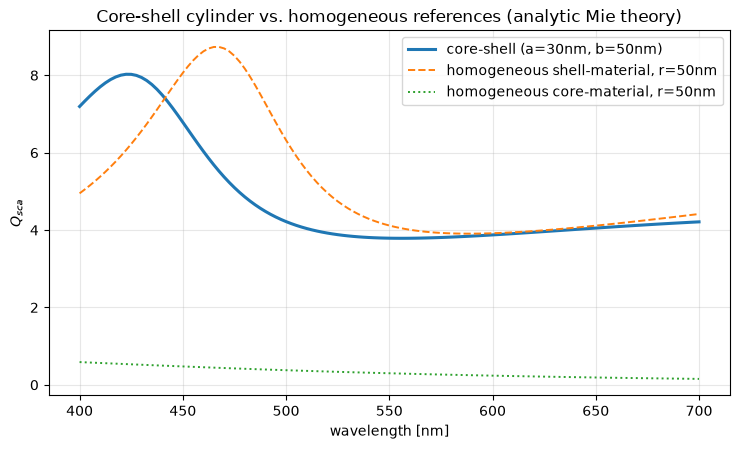

Peak Q_sca (core-shell): 8.026 at 422.5 nm


In [9]:
wls = np.linspace(400e-9, 700e-9, 121)
r_core, r_shell = 30e-9, 50e-9
eps_core, eps_shell = 2.1, 12.0

q_sca_cs, q_abs_cs, q_ext_cs = mie_coreshell_cylinder_Q(wls, r_core, r_shell, eps_core, eps_shell)
q_sca_shell_only, _, _ = mie_cylinder_Q(wls, r_shell, eps_shell)
q_sca_core_only, _, _ = mie_cylinder_Q(wls, r_shell, eps_core)

plt.figure(figsize=(7.5, 4.6))
plt.plot(wls*1e9, q_sca_cs, lw=2.2, label=f"core-shell (a={r_core*1e9:.0f}nm, b={r_shell*1e9:.0f}nm)")
plt.plot(wls*1e9, q_sca_shell_only, "--", lw=1.4, label=f"homogeneous shell-material, r={r_shell*1e9:.0f}nm")
plt.plot(wls*1e9, q_sca_core_only, ":", lw=1.4, label=f"homogeneous core-material, r={r_shell*1e9:.0f}nm")
plt.xlabel("wavelength [nm]")
plt.ylabel(r"$Q_{sca}$")
plt.title("Core-shell cylinder vs. homogeneous references (analytic Mie theory)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Peak Q_sca (core-shell):", f"{q_sca_cs.max():.3f} at {wls[np.argmax(q_sca_cs)]*1e9:.1f} nm")


### Near field

The same coefficients give the field $E_z(x, y)$ around the particle at a single wavelength. Here we look at the wavelength of the scattering peak. Inside the dashed square (the TFSF box) the map shows the total field. Outside the box it shows only the scattered field. This is the same convention the FDTD source uses, so the two maps can be compared directly later.

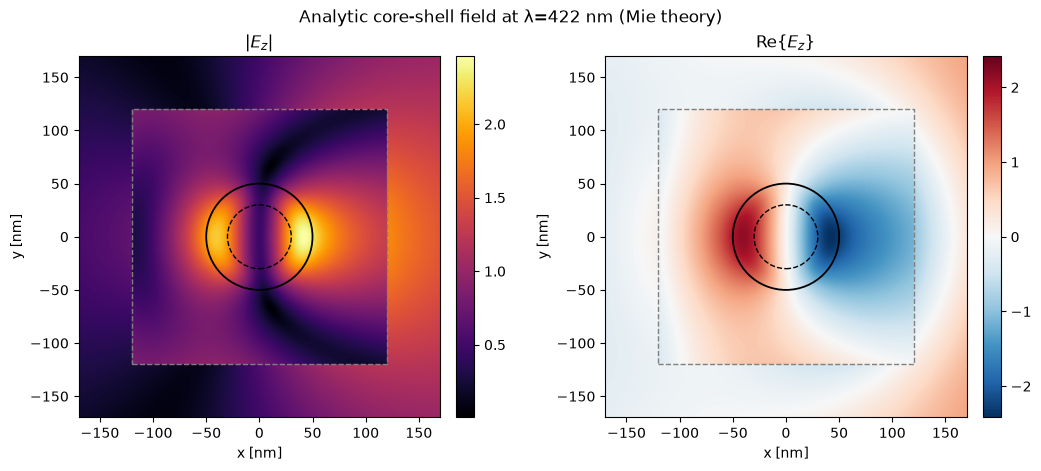

In [12]:
wl0 = wls[np.argmax(q_sca_cs)]     # look at the field right at the scattering peak
tfsf_xy = 240e-9
xs = np.linspace(-170e-9, 170e-9, 341)
ys = np.linspace(-170e-9, 170e-9, 341)

E = mie_coreshell_cylinder_field(xs, ys, wl0, r_core, r_shell, eps_core, eps_shell, tfsf_xy)
extent_nm = np.array([xs[0], xs[-1], ys[0], ys[-1]]) * 1e9

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.6), constrained_layout=True)
im0 = axes[0].imshow(np.abs(E).T, origin="lower", extent=extent_nm, cmap="inferno", aspect="equal")
axes[0].set_title(r"$|E_z|$")
fig.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)
lim = np.abs(E.real).max()
im1 = axes[1].imshow(E.real.T, origin="lower", extent=extent_nm, cmap="RdBu_r",
                      vmin=-lim, vmax=lim, aspect="equal")
axes[1].set_title(r"$\mathrm{Re}\{E_z\}$")
fig.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

for ax in axes:
    ax.add_patch(plt.Circle((0, 0), r_shell*1e9, fill=False, ec="k", lw=1.3))
    ax.add_patch(plt.Circle((0, 0), r_core*1e9, fill=False, ec="k", lw=1.0, ls="--"))
    ax.add_patch(plt.Rectangle((-tfsf_xy/2*1e9, -tfsf_xy/2*1e9), tfsf_xy*1e9, tfsf_xy*1e9,
                                fill=False, ec="0.5", ls="--", lw=1.0))
    ax.set_xlabel("x [nm]"); ax.set_ylabel("y [nm]")

fig.suptitle(f"Analytic core-shell field at \u03bb={wl0*1e9:.0f} nm (Mie theory)")
plt.show()


## Part 2: FDTD simulation

Now we run the same problem in `fdtdx`. The setup has these pieces:

- A plane-wave source in a total-field/scattered-field (TFSF) box around the particle. Inside the box the field is the total field, outside it only the scattered field remains. The source is a Gaussian pulse, so one run covers the whole 400–700 nm range.
- Two closed surfaces of Poynting-flux detectors. The one inside the TFSF box measures the absorbed power (net flux inward). The one outside measures the scattered power (net flux outward).
- PML boundaries in $x$ and $y$, and periodic boundaries in $z$.
- The particle itself, built from two concentric `fdtdx.Cylinder` objects. The outer one is filled with the shell material. The inner one has a higher `placement_order`, so it is applied afterwards and overwrites the middle of the shell with the core material.

In [15]:
from dataclasses import dataclass

import jax
import jax.numpy as jnp
import numpy as np
import fdtdx

get_ipython().run_line_magic("matplotlib", "inline")


@dataclass
class CoreShellSceneConfig:
    # --- particle geometry ---
    core_radius: float = 30e-9          # core radius a [m]
    shell_radius: float = 50e-9         # outer (shell) radius b [m]
    eps_core: float = 2.1               # core permittivity (silica-like)
    eps_shell: float = 12.0             # shell permittivity (silicon-like)

    # --- grid / domain ---
    resolution: float = 1.0e-9          # uniform grid spacing [m]
    core_xy: float = 340e-9             # core (non-PML) transverse size [m]
    pml_cells: int = 10                 # PML thickness in cells (x and y)
    center_wl: float = 560e-9           # pulse carrier wavelength [m]
    sim_time: float = 25e-15            # max simulation time [s]
    backend: str = "gpu"                 # "gpu"/"tpu"/"cpu"/"METAL"; fdtdx resolves this
                                          # against whatever JAX backend is actually
                                          # available, so "gpu" is a safe default even
                                          # when running on a CPU-only machine.

    # Concentric box sizes (must satisfy: inside < tfsf < outside < core_xy).
    tfsf_xy: float = 240e-9             # TFSF source box transverse size [m]
    inside_xy: float = 230e-9           # absorbed-power box (in total-field region)
    outside_xy: float = 250e-9          # scattered-power box (in scattered-field region)
    inc_plane_xy: float = 200e-9        # incident-irradiance probe width [m]

    # Wavelengths at which to evaluate the phasor detectors / cross sections.
    n_wl: int = 9
    wl_min: float = 400e-9
    wl_max: float = 700e-9


def _wavelengths(cfg: CoreShellSceneConfig):
    return np.linspace(cfg.wl_min, cfg.wl_max, cfg.n_wl)


### Scene setup

`CoreShellSceneConfig` collects all parameters of the simulation: particle radii and permittivities, grid resolution, domain size, and the sizes of the source and detector boxes. `build_scene` turns such a config into an FDTDX scene. With `with_particle=False` it leaves out the particle, which gives the empty reference scene we need for the incident irradiance.

The scene consists of the following parts:

- **Domain and boundaries.** The simulation volume is a thin slab, only two cells thick in z, since the problem is invariant along the cylinder axis. The boundaries are periodic in z and PML in x and y.
- **Source.** A broadband Gaussian pulse centered at 560 nm is injected by a total-field/scattered-field (TFSF) box. It travels along +x with the E-field along z. Inside the box we have the total field (incident plus scattered), outside only the scattered field.
- **Particle.** The core-shell cylinder is built from two concentric cylinders. We first fill the whole disk with the shell material (`placement_order=0`) and then place the core on top (`placement_order=1`), which overwrites the inner part. Both materials are non-dispersive, so the FDTD result can be compared directly with the analytic theory from Part 1.
- **Absorbed power.** A closed surface of flux detectors lies inside the TFSF box around the particle. It is oriented inward, so the net flux through it is the power absorbed by the particle.
- **Scattered power.** A second closed surface lies outside the TFSF box and is oriented outward. Here the net flux is the scattered power.
- **Incident irradiance.** A flux plane inside the TFSF box, a little upstream of the particle, measures the incident power per unit area. In the reference run (no particle) this plane also lets us check that the TFSF box cancels correctly.
- **Field map.** A phasor detector records the complex E_z field in the xy-plane at the center wavelength. An optional energy detector records a video of the pulse.

All flux detectors evaluate the response at the same set of wavelengths, so a single run gives us the full spectrum.

In [18]:
def build_scene(cfg: CoreShellSceneConfig, key, with_particle: bool, generate_video: bool = False):
    """Build the scene: boundaries, TFSF source, detectors and the particle.

    With with_particle=False the scene is empty and serves as the reference run.
    The core-shell particle is two concentric cylinders: the shell is placed
    first and the core is placed on top, overwriting the inner disk of the shell.
    """
    TE_POL = (0.0, 0.0, 1.0)  # E along the cylinder axis (z) -> TM / E-parallel

    total_xy = cfg.core_xy + 2 * cfg.pml_cells * cfg.resolution
    Lz = 2 * cfg.resolution

    sim_config = fdtdx.SimulationConfig(
        time=cfg.sim_time,
        grid=fdtdx.UniformGrid(spacing=cfg.resolution),
        backend=cfg.backend,
        dtype=jnp.float32,
        courant_factor=0.99,
        gradient_config=None,  # forward-only scattering run; no reversibility needed
    )

    volume = fdtdx.SimulationVolume(
        partial_real_shape=(total_xy, total_xy, Lz),
        material=fdtdx.Material(),  # vacuum background
        name="volume",
    )
    object_list: list = [volume]
    constraints = []

    # Boundaries: PML on x, y ; periodic on z.
    bound_cfg = fdtdx.BoundaryConfig.from_uniform_bound(
        thickness=cfg.pml_cells,
        boundary_type="pml",
        override_types={"min_z": "periodic", "max_z": "periodic"},
    )
    bdict, bconstraints = fdtdx.boundary_objects_from_config(bound_cfg, volume)
    object_list.extend(bdict.values())
    constraints.extend(bconstraints)

    # Broadband Gaussian pulse -> one run yields the response across a band.
    center_character = fdtdx.WaveCharacter(wavelength=cfg.center_wl)
    width_character = fdtdx.WaveCharacter(frequency=center_character.get_frequency() / 5)
    profile = fdtdx.GaussianPulseProfile(
        center_wave=center_character,
        spectral_width=width_character,
    )

    # --- TFSF box source: total field inside, scattered field outside. ---
    source = fdtdx.TFSFPlaneSourceRegion(
        name="source",
        partial_real_shape=(cfg.tfsf_xy, cfg.tfsf_xy, None),
        propagation_axis=0,                 # +x
        direction="+",
        wave_character=fdtdx.WaveCharacter(wavelength=cfg.center_wl),
        temporal_profile=profile,
        fixed_E_polarization_vector=TE_POL,
        amplitude=1.0,
        periodic_axes=(2,),                 # z is periodic/wrap -> box spans full z
    )
    object_list.append(source)
    constraints += [
        source.place_at_center(volume),
        source.same_size(volume, axes=(2,)),
    ]

    # --- Core-shell cylinder (axis along z), spanning the whole z extent. ---
    # Both materials are simple non-dispersive dielectrics here so the FDTD
    # result can be compared *exactly* against the analytic theory in Part 1
    # (no eps(wavelength) model to align between the two).
    if with_particle:
        vacuum_mat = fdtdx.Material()
        shell_mat = fdtdx.Material(permittivity=cfg.eps_shell)
        core_mat = fdtdx.Material(permittivity=cfg.eps_core)

        # 1) Fill the full outer disk (radius = shell_radius) with the shell material.
        shell_cyl = fdtdx.Cylinder(
            radius=cfg.shell_radius,
            axis=2,
            material_name="shell",
            materials={"vacuum": vacuum_mat, "shell": shell_mat},
            name="shell_cyl",
            placement_order=0,
        )
        object_list.append(shell_cyl)
        constraints += [
            shell_cyl.place_at_center(volume),
            shell_cyl.same_size(volume, axes=(2,)),
        ]

        # 2) Stamp the inner disk (radius = core_radius) with the core material on top.
        core_cyl = fdtdx.Cylinder(
            radius=cfg.core_radius,
            axis=2,
            material_name="core",
            materials={"vacuum": vacuum_mat, "core": core_mat},
            name="core_cyl",
            placement_order=1,
        )
        object_list.append(core_cyl)
        constraints += [
            core_cyl.place_at_center(volume),
            core_cyl.same_size(volume, axes=(2,)),
        ]

    # --- Absorbed power: closed surface INSIDE the TFSF box, around particle. ---
    inside = fdtdx.ClosedSurfacePhasorPoyntingFluxDetector(
        name="inside",
        partial_real_shape=(cfg.inside_xy, cfg.inside_xy, None),
        orientation="inward",               # net inward flux = absorbed power
        axes=(0, 1),                        # z-face pair cancels (periodic); 4 faces
        wave_characters=[fdtdx.WaveCharacter(wavelength=float(w)) for w in _wavelengths(cfg)],
        scaling_mode="pulse",
    )
    object_list.append(inside)
    constraints += [
        inside.place_at_center(volume),
        inside.same_size(volume, axes=(2,)),
    ]

    # --- Scattered power: closed surface OUTSIDE the TFSF box. ---
    outside = fdtdx.ClosedSurfacePhasorPoyntingFluxDetector(
        name="outside",
        partial_real_shape=(cfg.outside_xy, cfg.outside_xy, None),
        orientation="outward",              # net outward flux = scattered power
        axes=(0, 1),
        wave_characters=[fdtdx.WaveCharacter(wavelength=float(w)) for w in _wavelengths(cfg)],
        scaling_mode="pulse",
    )
    object_list.append(outside)
    constraints += [
        outside.place_at_center(volume),
        outside.same_size(volume, axes=(2,)),
    ]

    # --- Incident irradiance probe: a +x flux plane inside the TFSF box. ---
    inc = fdtdx.PhasorPoyntingFluxDetector(
        name="inc",
        direction="+",
        partial_grid_shape=(1, None, None),
        partial_real_shape=(None, cfg.inc_plane_xy, None),
        wave_characters=[fdtdx.WaveCharacter(wavelength=float(w)) for w in _wavelengths(cfg)],
        scaling_mode="pulse",
    )
    object_list.append(inc)
    constraints += [
        inc.place_at_center(volume, axes=(1, 2)),
        inc.same_size(volume, axes=(2,)),
        # a little upstream of centre, still well inside the TFSF box
        inc.place_relative_to(
            volume, axes=(0,), own_positions=(0.0,), other_positions=(0.0,),
            margins=(-cfg.tfsf_xy / 4,),
        ),
    ]

    phasor = fdtdx.PhasorDetector(
        name="phasor",
        components=["Ez"],
        partial_grid_shape=(None, None, 1),
        wave_characters=[center_character],
        plot=False,
    )
    object_list.append(phasor)
    constraints.append(phasor.place_at_center(volume))
    constraints.append(phasor.same_size(volume, axes=(0, 1)))

    if generate_video:
        energy_video = fdtdx.EnergyDetector(
            name="energy_video",
            as_slices=True,
            inverse=False,
            switch=fdtdx.OnOffSwitch(interval=30)
        )
        object_list.append(energy_video)
        constraints.extend(energy_video.same_position_and_size(volume))

    objects, arrays, params, sim_config, info = fdtdx.place_objects(
        object_list=object_list,
        config=sim_config,
        constraints=constraints,
        key=key,
    )

    return {
        "objects": objects,
        "arrays": arrays,
        "params": params,
        "config": sim_config,
        "cfg": cfg,
        "inc_plane_area": cfg.inc_plane_xy * Lz,
        "Lz": Lz,
    }


### Helper functions

These functions wrap the FDTDX calls we need to run a scene and read out the results.

- `run_forward` applies the parameters to the scene (this also sets up the source and detector objects) and runs the FDTD simulation. It returns the final arrays that contain the detector states. The progress bar is off by default because it can hang when the notebook is executed headless, for example with `nbconvert`. You can switch it on if you run the notebook interactively.
- `extract_fluxes` reads the three flux detectors and returns the net scattered power, the net absorbed power and the incident power through the probe plane, each as one value per wavelength.
- `extract_phasor` returns the complex E_z phasor on the xy-plane together with its physical extent in nm, which is what we need for plotting the field map.

In [21]:
def run_forward(scene, key, show_progress=False):
    """Populate source state, run the forward FDTD, return the final arrays.

    show_progress is off by default because the progress bar can hang when the
    notebook is executed headless (for example with nbconvert). Turn it on if
    you run the notebook interactively.
    """
    arrays, objects, _ = fdtdx.apply_params(
        scene["arrays"], scene["objects"], scene["params"], key
    )
    scene["objects"] = objects  # keep the applied source/detector objects

   
    _, arrays = fdtdx.run_fdtd(
        arrays=arrays,
        objects=objects,
        config=scene["config"],
        key=key,
        show_progress=show_progress,
    )
    return arrays


def _detector_by_name(objects, name):
    return {d.name: d for d in objects.detectors}[name]


def extract_fluxes(scene, arrays):
    """Return dict of per-wavelength net fluxes: scattered, absorbed, incident."""
    objects = scene["objects"]
    states = arrays.detector_states

    outside_det = _detector_by_name(objects, "outside")
    inside_det = _detector_by_name(objects, "inside")
    inc_det = _detector_by_name(objects, "inc")

    p_scat = np.asarray(outside_det.compute_net_flux(states["outside"]))     # (n_wl,)
    p_abs = np.asarray(inside_det.compute_net_flux(states["inside"]))        # (n_wl,)
    p_inc_plane = np.asarray(inc_det.compute_poynting_flux(states["inc"]))   # (n_wl,)

    return {"p_scat": p_scat, "p_abs": p_abs, "p_inc_plane": p_inc_plane}


def extract_phasor(scene, arrays):
    """Return the complex Ez phasor on the xy-plane and its physical extent [nm]."""
    raw = np.asarray(arrays.detector_states["phasor"]["phasor"])
    # (latent=1, n_wl=1, n_comp=1, nx, ny, nz=1) -> (nx, ny)
    Ez = raw[0, 0, 0, :, :, 0]

    nx, ny = Ez.shape
    res = scene["cfg"].resolution
    Lx, Ly = nx * res, ny * res
    extent_nm = np.array([-Lx / 2.0, Lx / 2.0, -Ly / 2.0, Ly / 2.0]) * 1e9
    return Ez, extent_nm


### Running the simulations and comparing spectra

We run the simulation twice. The first run has no particle. It gives the incident irradiance, and it also checks the TFSF box: with nothing inside, the outer detector should see almost no scattered power. The second run includes the core–shell particle.

Dividing the measured power by the incident irradiance gives the cross sections, and dividing by $2b$ gives the efficiencies $Q$. We plot them against the analytic result from Part 1.

TFSF leakage (should be << 1): max = 1.414e-10

 wl[nm]     Q_sca  FDTD/Mie      Q_abs  FDTD/Mie      Q_ext  FDTD/Mie
  400.0    7.1902/7.1932     0.0121/-0.0000    7.2023/7.1932 
  437.5    7.6674/7.6360     0.0104/0.0000     7.6778/7.6360 
  475.0    5.1244/5.0955     0.0046/0.0000     5.1290/5.0955 
  512.5    4.0210/4.0045     0.0034/0.0000     4.0244/4.0045 
  550.0    3.8008/3.7891     0.0026/0.0000     3.8033/3.7891 
  587.5    3.8479/3.8366     0.0007/0.0000     3.8486/3.8366 
  625.0    3.9712/3.9601     0.0012/-0.0000    3.9723/3.9601 
  662.5    4.1067/4.0948     0.0003/0.0000     4.1070/4.0948 
  700.0    4.2236/4.2113    -0.0004/-0.0000    4.2233/4.2113 


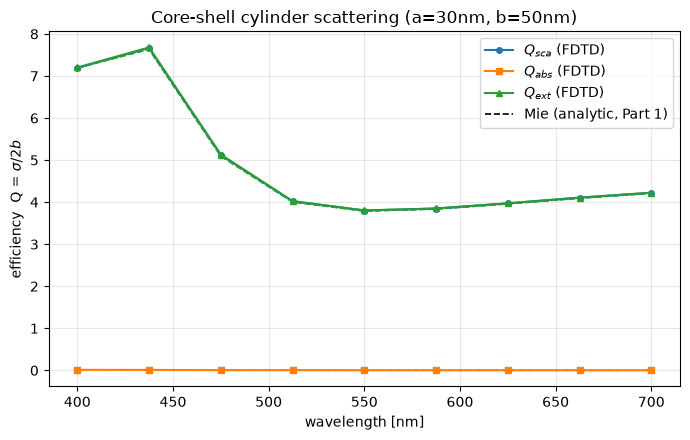


Saved spectrum to coreshell_outputs/coreshell_scattering_spectrum.png


In [24]:
import pathlib

cfg = CoreShellSceneConfig()
wls_fdtd = _wavelengths(cfg)
key = jax.random.PRNGKey(42)

out_dir = pathlib.Path("coreshell_outputs")
out_dir.mkdir(exist_ok=True)

# Reference run (no particle): incident irradiance + TFSF-cancellation check.
ref_scene = build_scene(cfg, key, with_particle=False)
ref_arrays = run_forward(ref_scene, key)
ref = extract_fluxes(ref_scene, ref_arrays)

# Scattering run (with the core-shell particle).
scene = build_scene(cfg, key, with_particle=True)
arrays = run_forward(scene, key)
sca = extract_fluxes(scene, arrays)

# Incident irradiance [W/m^2] from the reference run (pure incident field).
incident_irradiance = ref["p_inc_plane"] / ref_scene["inc_plane_area"]

# Sanity: without a scatterer the scattered-field box should be ~0.
leak = np.abs(ref["p_scat"]) / (np.abs(sca["p_scat"]) + 1e-30)
print(f"TFSF leakage (should be << 1): max = {leak.max():.3e}")

# Cross sections (per unit z-length).
Lz = scene["Lz"]
sigma_sca = (sca["p_scat"] / Lz) / incident_irradiance
sigma_abs = (sca["p_abs"] / Lz) / incident_irradiance
sigma_ext = sigma_sca + sigma_abs

# 2D scattering efficiency Q = sigma / (2 * outer_radius).
q_sca = sigma_sca / (2 * cfg.shell_radius)
q_abs = sigma_abs / (2 * cfg.shell_radius)
q_ext = sigma_ext / (2 * cfg.shell_radius)

# --- Analytic core-shell Mie reference, reusing the Part 1 functions directly. ---
q_sca_mie, q_abs_mie, q_ext_mie = mie_coreshell_cylinder_Q(
    wls_fdtd, cfg.core_radius, cfg.shell_radius, cfg.eps_core, cfg.eps_shell
)

print("\n wl[nm]     Q_sca  FDTD/Mie      Q_abs  FDTD/Mie      Q_ext  FDTD/Mie")
for w, qs, qa, qe, ms_, ma, me in zip(wls_fdtd, q_sca, q_abs, q_ext, q_sca_mie, q_abs_mie, q_ext_mie):
    print(f" {w*1e9:6.1f}   {qs:7.4f}/{ms_:<7.4f}   {qa:7.4f}/{ma:<7.4f}   {qe:7.4f}/{me:<7.4f}")

plt.figure(figsize=(7, 4.5))
plt.plot(wls_fdtd * 1e9, q_sca, "-o", ms=4, label=r"$Q_{sca}$ (FDTD)")
plt.plot(wls_fdtd * 1e9, q_abs, "-s", ms=4, label=r"$Q_{abs}$ (FDTD)")
plt.plot(wls_fdtd * 1e9, q_ext, "-^", ms=4, label=r"$Q_{ext}$ (FDTD)")
plt.gca().set_prop_cycle(None)
plt.plot(wls_fdtd * 1e9, q_sca_mie, "--", lw=1.2)
plt.plot(wls_fdtd * 1e9, q_abs_mie, "--", lw=1.2)
plt.plot(wls_fdtd * 1e9, q_ext_mie, "--", lw=1.2)
plt.plot([], [], "k--", lw=1.2, label="Mie (analytic, Part 1)")
plt.xlabel("wavelength [nm]")
plt.ylabel("efficiency  Q = $\\sigma / 2b$")
plt.title(f"Core-shell cylinder scattering (a={cfg.core_radius*1e9:.0f}nm, b={cfg.shell_radius*1e9:.0f}nm)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(out_dir / "coreshell_scattering_spectrum.png", dpi=140)
plt.show()
print(f"\nSaved spectrum to {out_dir / 'coreshell_scattering_spectrum.png'}")

### Near-field comparison

The left panel shows $|E_z|$ from the FDTD phasor detector, normalized with the incident amplitude from the reference run. The middle panel shows the analytic field from Part 1 and the right panel a line cut through $y = 0$.

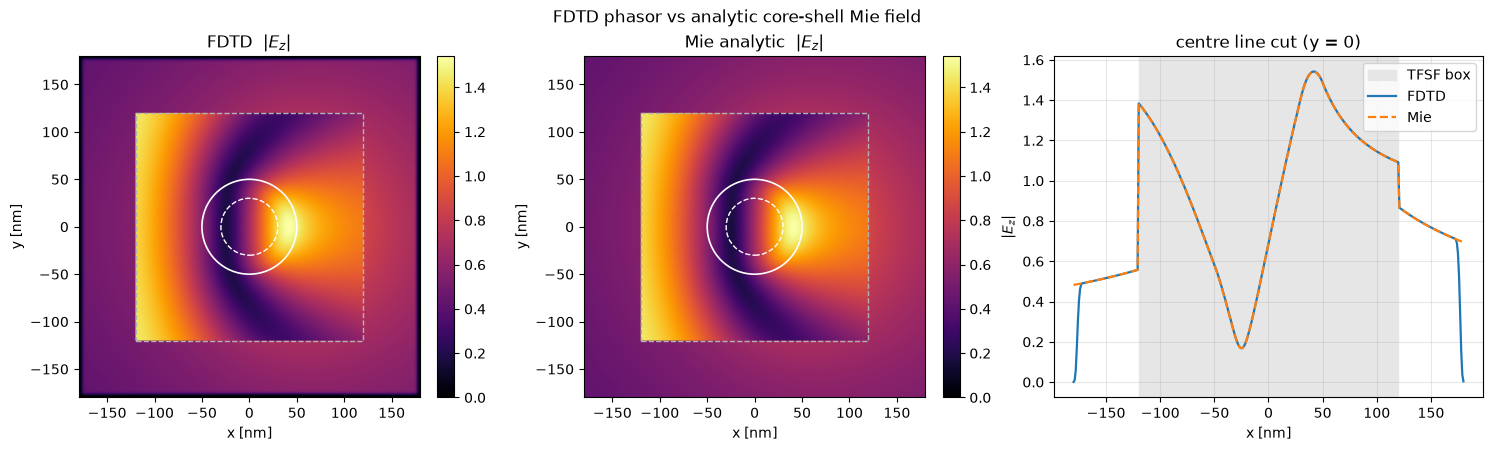

Saved field comparison to coreshell_outputs/coreshell_phasor_vs_mie.png


In [27]:
# --- Phasor field map: Ez at the carrier wavelength (with particle). ---
Ez_sca, extent_nm = extract_phasor(scene, arrays)
Ez_ref, _ = extract_phasor(ref_scene, ref_arrays)

# Normalise the FDTD phasor to unit incident amplitude using the reference run
# (pure plane wave -> |E| is ~constant inside the box).
nx, ny = Ez_sca.shape
xs = (np.arange(nx) - (nx - 1) / 2) * cfg.resolution        # cell centres [m]
ys = (np.arange(ny) - (ny - 1) / 2) * cfg.resolution
Xg, Yg = np.meshgrid(xs, ys, indexing="ij")
box = (np.abs(Xg) <= cfg.tfsf_xy / 2) & (np.abs(Yg) <= cfg.tfsf_xy / 2)
E0 = np.mean(np.abs(Ez_ref)[box])
Ez_fdtd_norm = Ez_sca / E0

# Analytic core-shell field at the same wavelength / grid.
E_mie = mie_coreshell_cylinder_field(
    xs, ys, cfg.center_wl, cfg.core_radius, cfg.shell_radius,
    cfg.eps_core, cfg.eps_shell, cfg.tfsf_xy,
)

a_f, a_m = np.abs(Ez_fdtd_norm).T, np.abs(E_mie).T
vmax = float(max(a_f.max(), a_m.max()))
r_core_nm, r_shell_nm, half = cfg.core_radius * 1e9, cfg.shell_radius * 1e9, cfg.tfsf_xy / 2 * 1e9

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
for ax, dat, ttl in ((axes[0], a_f, r"FDTD  $|E_z|$"), (axes[1], a_m, r"Mie analytic  $|E_z|$")):
    im = ax.imshow(dat, origin="lower", extent=extent_nm, cmap="inferno",
                    vmin=0, vmax=vmax, interpolation="bilinear", aspect="equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.add_patch(plt.Circle((0, 0), r_shell_nm, fill=False, ec="w", lw=1.2))
    ax.add_patch(plt.Circle((0, 0), r_core_nm, fill=False, ec="w", lw=1.0, ls="--"))
    ax.add_patch(plt.Rectangle((-half, -half), 2 * half, 2 * half, fill=False, ec="0.7", ls="--", lw=1.0))
    ax.set_title(ttl)
    ax.set_xlabel("x [nm]")
    ax.set_ylabel("y [nm]")

jy = ny // 2  # y = 0 row
xnm = np.linspace(extent_nm[0], extent_nm[1], nx)
axes[2].axvspan(-half, half, color="0.9", zorder=0, label="TFSF box")
axes[2].plot(xnm, np.abs(Ez_fdtd_norm[:, jy]), "-", lw=1.6, label="FDTD")
axes[2].plot(xnm, np.abs(E_mie[:, jy]), "--", lw=1.6, label="Mie")
axes[2].set_xlabel("x [nm]")
axes[2].set_ylabel(r"$|E_z|$")
axes[2].set_title("centre line cut (y = 0)")
axes[2].legend()
axes[2].grid(alpha=0.3)

fig.suptitle("FDTD phasor vs analytic core-shell Mie field")
fig.savefig(out_dir / "coreshell_phasor_vs_mie.png", dpi=140)
plt.show()
print(f"Saved field comparison to {out_dir / 'coreshell_phasor_vs_mie.png'}")


## Appendix

Mie theory for a core–shell cylinder. This appendix contains the math behind the analytic functions in Part 1.

### Fields

All materials have $\mu = 1$. The core ($r < a$) has permittivity $\varepsilon_1$, the shell ($a < r < b$) has $\varepsilon_2$, and the surrounding medium has $\varepsilon_m$ (vacuum by default). Let $k_0 = 2\pi\sqrt{\varepsilon_m}/\lambda$ be the wave number in the medium, and let $k_1 = k_0\sqrt{\varepsilon_1/\varepsilon_m}$ and $k_2 = k_0\sqrt{\varepsilon_2/\varepsilon_m}$ be the wave numbers in the core and the shell. For a wave travelling along $+x$ with $\mathbf{E}$ along $z$, the field in the three regions is expanded in cylindrical waves:

- Core ($r < a$): $E_z = \sum_n c_n\, J_n(k_1 r)\, e^{in\phi}$
- Shell ($a < r < b$): $E_z = \sum_n \big[d_n J_n(k_2 r) + e_n Y_n(k_2 r)\big]\, e^{in\phi}$
- Medium ($r > b$): $E_z = \sum_n i^n\big[J_n(k_0 r) + a_n H_n^{(1)}(k_0 r)\big]\, e^{in\phi}$

Here $J_n$ and $Y_n$ are Bessel functions of the first and second kind, and $H_n^{(1)}$ is the Hankel function of the first kind. The coefficients $a_n$ describe the scattered wave, and they are what we need.

### Boundary conditions

At $r = a$ and $r = b$, both $E_z$ and $\partial E_z/\partial r$ must be continuous. Since $\mu = 1$ everywhere, the second condition is the same as continuity of $H_\phi$. After factoring out the common $i^n$, each order $n$ gives a $4\times4$ linear system for $(c_n, d_n, e_n, a_n)$:

$$
\begin{pmatrix}
J_n(k_1 a) & -J_n(k_2 a) & -Y_n(k_2 a) & 0 \\
k_1 J_n'(k_1 a) & -k_2 J_n'(k_2 a) & -k_2 Y_n'(k_2 a) & 0 \\
0 & J_n(k_2 b) & Y_n(k_2 b) & -H_n^{(1)}(k_0 b) \\
0 & k_2 J_n'(k_2 b) & k_2 Y_n'(k_2 b) & -k_0 H_n^{(1)\prime}(k_0 b)
\end{pmatrix}
\begin{pmatrix} c_n \\ d_n \\ e_n \\ a_n \end{pmatrix}
=
\begin{pmatrix} 0 \\ 0 \\ J_n(k_0 b) \\ k_0 J_n'(k_0 b) \end{pmatrix}
$$

A solid cylinder has a simple closed formula for $a_n$. With two interfaces there is no such formula, but a $4\times4$ solve per order is cheap. The sums are cut off at an order of about $x + 4x^{1/3} + 2$, with a few extra terms added, where $x = k_0 b$.

### Efficiencies

Once the $a_n$ are known, the efficiencies follow in the same way as for a solid cylinder, using the outer radius $b$ as the size reference:

$$
Q_{sca} = \frac{2}{x}\Big(|a_0|^2 + 2\sum_{n\ge1}|a_n|^2\Big), \qquad
Q_{ext} = -\frac{2}{x}\,\mathrm{Re}\Big(a_0 + 2\sum_{n\ge1}a_n\Big), \qquad x = k_0 b
$$

and $Q_{abs} = Q_{ext} - Q_{sca}$.

### Limiting cases

The solution has to reduce to the solid-cylinder formula when $\varepsilon_1 = \varepsilon_2$ (the inner interface disappears), when $a \to 0$ (no core) and when $a \to b$ (no shell). These are the first three checks in Part 1.

### Field maps

For the near-field plots, the three series above are evaluated at each grid point. The incident wave $e^{ik_0 x}$ is then subtracted everywhere outside the TFSF box, which leaves only the scattered field there, as in the simulation.